<a href="https://colab.research.google.com/github/rodrigoambar/credit-card-fraud-detection/blob/main/deteccao_anomalias_curso_dio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
finance_transactions = pd.read_csv('https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv')
finance_transactions.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


/tmp/ipykernel_10978/1597635424.py:1: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  contagem_resultados = pd.value_counts(finance_transactions['Class'], sort = True, normalize= True)


<Axes: title={'center': 'Contagem dos tipos de transação: Fraudes = 1 Normais = 0'}, xlabel='Class'>

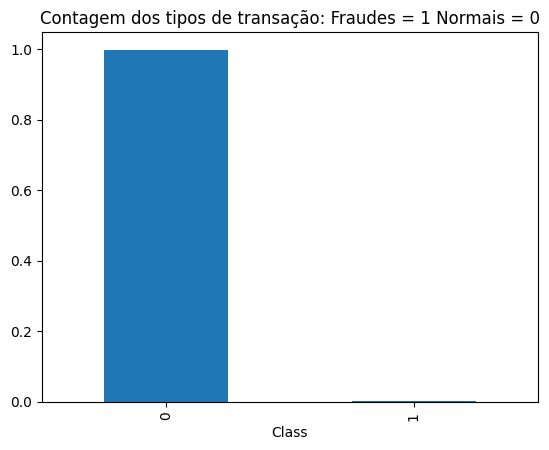

In [ ]:
contagem_resultados = pd.value_counts(finance_transactions['Class'], sort = True, normalize= True)
contagem_resultados.plot(kind = 'bar', title = 'Contagem dos tipos de transação: Fraudes = 1 Normais = 0')



<Axes: >

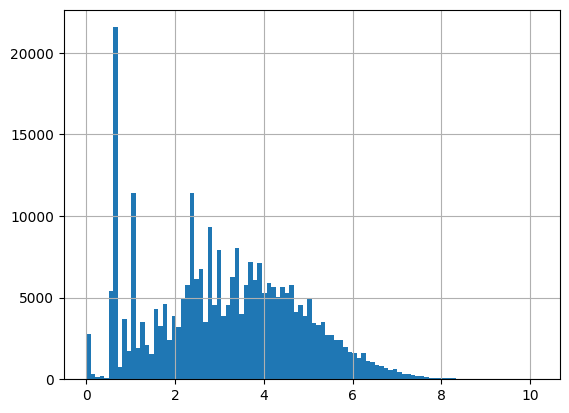

In [ ]:
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Criar transformação logarítmica do valor
finance_transactions['Amount_log'] = np.log1p(
    finance_transactions['Amount']
)

# Visualizar distribuição
finance_transactions['Amount_log'].hist(bins=100)


In [ ]:
# Separar variáveis explicativas e variável-alvo
X = finance_transactions.drop(
    columns=['Class']
)

y = finance_transactions['Class']

# Separar treino e teste mantendo proporção das fraudes
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

print("\nProporção de fraudes:")
print("Treino:", y_train.mean())
print("Teste:", y_test.mean())


Treino: (227845, 31)
Teste: (56962, 31)

Proporção de fraudes:
Treino: 0.001729245759178389
Teste: 0.0017204452090867595


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Criar pipeline
modelo_logistico = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

# Treinar
modelo_logistico.fit(X_train, y_train)

# Previsões
pred_logistico = modelo_logistico.predict(X_test)
prob_logistico = modelo_logistico.predict_proba(X_test)[:, 1]
print("Previsões:", pred_logistico)
print("Probabilidades:", prob_logistico)

Previsões: [0 0 0 ... 0 0 0]
Probabilidades: [0.00598138 0.06493367 0.00013852 ... 0.00025018 0.00367956 0.08659776]


In [ ]:
#Medindo com random forest
from sklearn.ensemble import RandomForestClassifier
import time

inicio_execucao = time.time()

modelo_rf = RandomForestClassifier(
    n_estimators=50,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

modelo_rf.fit(X_train, y_train)

pred_rf = modelo_rf.predict(X_test)
prob_rf = modelo_rf.predict_proba(X_test)[:, 1]

fim_execucao = time.time()

print(f"Tempo de execução: {fim_execucao - inicio_execucao:.2f} segundos")
print("Previsões:", pred_rf)
print("Probabilidades:", prob_rf)


Tempo de execução: 63.25 segundos
Previsões: [0 0 0 ... 0 0 0]
Probabilidades: [0.00782852 0.05071813 0.02464692 ... 0.00847198 0.01400803 0.05867518]


In [ ]:
from xgboost import XGBClassifier

# Calcular proporção entre classes
peso_fraude = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

modelo_xgb = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=peso_fraude,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

modelo_xgb.fit(X_train, y_train)

pred_xgb = modelo_xgb.predict(X_test)
prob_xgb = modelo_xgb.predict_proba(X_test)[:, 1]
print("Previsões:", pred_xgb)
print("Probabilidades:", prob_xgb)

Previsões: [0 0 0 ... 0 0 0]
Probabilidades: [0.00015401 0.00037635 0.0091591  ... 0.00033259 0.00041147 0.00071105]


In [ ]:

from sklearn.metrics import classification_report

print("REGRESSÃO LOGÍSTICA")
print(classification_report(y_test, pred_logistico))

print("RANDOM FOREST")
print(classification_report(y_test, pred_rf))

print("XGBOOST")
print(classification_report(y_test, pred_xgb))


REGRESSÃO LOGÍSTICA
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962

RANDOM FOREST
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.69      0.85      0.76        98

    accuracy                           1.00     56962
   macro avg       0.84      0.92      0.88     56962
weighted avg       1.00      1.00      1.00     56962

XGBOOST
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.52      0.86      0.65        98

    accuracy                           1.00     56962
   macro avg       0.76      0.93      0.82     56962
weighted avg       1.00      1.0

In [ ]:
import shap
import matplotlib.pyplot as plt
import numpy as np

# Criar explicador SHAP para o Random Forest
explainer = shap.TreeExplainer(modelo_rf)

# Calcular valores SHAP utilizando uma amostra do conjunto de teste
X_shap = X_test.sample(
    n=min(2000, len(X_test)),
    random_state=42
)

shap_values = explainer.shap_values(X_shap)

# Verificar estrutura dos valores SHAP
print("Tipo:", type(shap_values))

if isinstance(shap_values, list):
    # Formato utilizado em algumas versões do SHAP
    shap_fraude = shap_values[1]

elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    # Formato: amostras x variáveis x classes
    shap_fraude = shap_values[:, :, 1]

else:
    # Formato bidimensional
    shap_fraude = shap_values

print("Formato dos valores SHAP:", shap_fraude.shape)
print("Formato dos dados:", X_shap.shape)


Tipo: <class 'numpy.ndarray'>
Formato dos valores SHAP: (2000, 31)
Formato dos dados: (2000, 31)


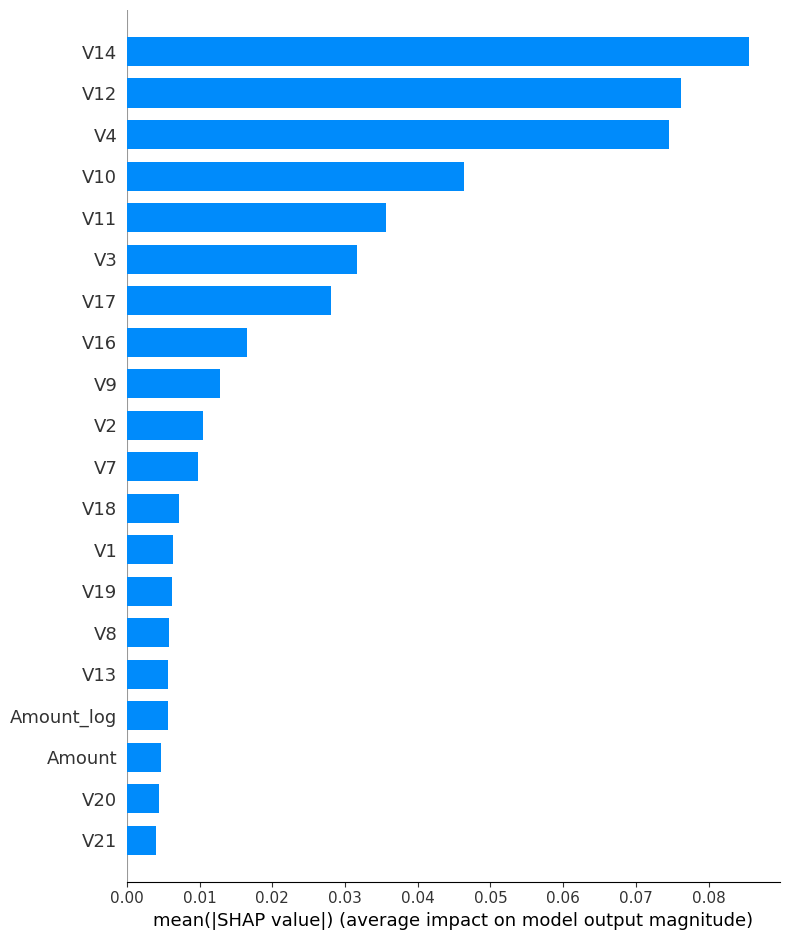

In [ ]:
# Selecionar os valores SHAP da classe de fraude
if isinstance(shap_values, list):
    shap_fraude = shap_values[1]
elif shap_values.ndim == 3:
    shap_fraude = shap_values[:, :, 1]
else:
    shap_fraude = shap_values

# Gráfico de importância
shap.summary_plot(
    shap_fraude,
    X_test,
    plot_type="bar"
)

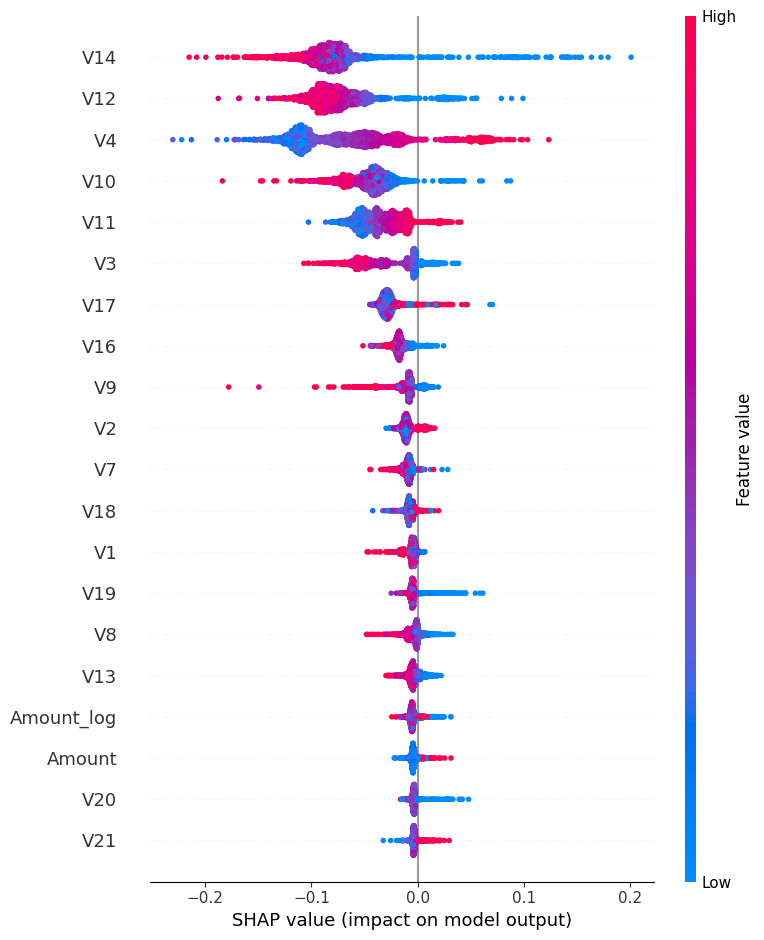

In [ ]:
# gráfico de Beeswarm
shap.summary_plot(
    shap_fraude,
    X_shap
)
